# Isolated-cell bioelectric model

Equation 4: C(dV/dt) = -I_{pol}(V)-I_{dep}(V)

Goal:
1. Implement Equation 4 independently.
2. Verify against hand calculations.
3. Plot the current-voltage relationship.
4. Identify equilibrium membrane potentials.

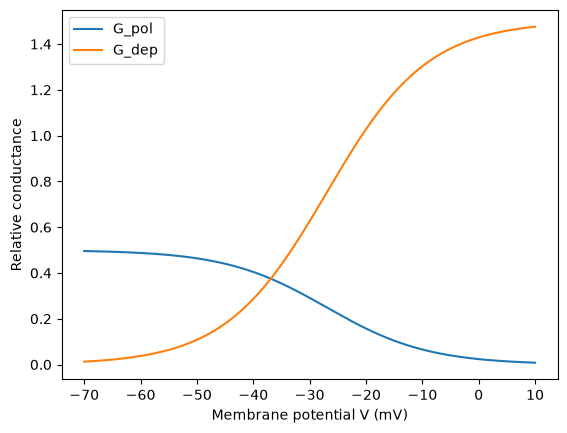

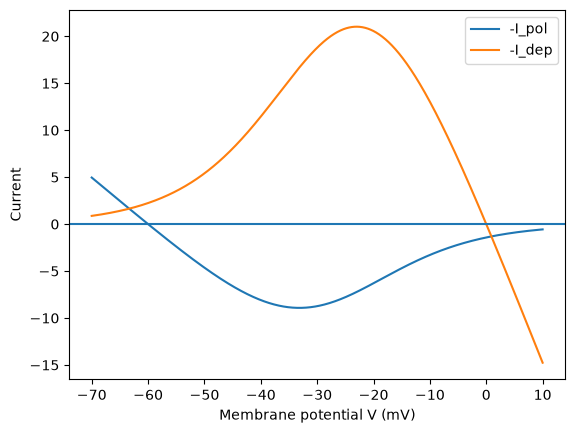

0.487537786676443 0.037386639970671064
0.4045709778775673 0.2862870663672982
0.25 0.75
0.10430426366302248 1.1870872090109326
0.02371293658878339 1.4288611902336499
-60 -I_pol = -0.0 -I_dep = 2.243198398240264 net = 2.243198398240264
-40 -I_pol = -8.091419557551346 -I_dep = 11.45148265469193 net = 3.360063097140584
-27 -I_pol = -8.25 -I_dep = 20.25 net = 12.0
-15 -I_pol = -4.693691864836012 -I_dep = 17.806308135163988 net = 13.112616270327976
0 -I_pol = -1.4227761953270035 -I_dep = -0.0 net = -1.4227761953270035


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

E_pol = -60.0
E_dep = 0.0

V_th_pol = -27.0
V_th_dep = -27.0

z_pol = 3.0
z_dep = -3.0

V_T = 27.0

G_pol_0 = 0.5
G_dep_0 = 1.5



def G_pol(V):
    return G_pol_0 / (1 + np.exp((V - V_th_pol) * z_pol / V_T))

def I_pol(V):
    return G_pol(V) * (V - E_pol)

def G_dep(V):
    return G_dep_0 / (1 + np.exp((V - V_th_dep) * z_dep / V_T))

def I_dep(V):
    return G_dep(V) * (V - E_dep)

def C_dVdt(V):
    return (- I_pol(V) - I_dep(V))

# Having a capacitance value is important for calculating the rate of change of voltage over time. 
# The following function can be used to compute dV/dt given a specific capacitance C:
# the above function C_dVdt(V) returns the total current (I_pol + I_dep) at a given voltage V, 
# which can be used to compute dV/dt by dividing by the capacitance C.
#  def dVdt(V, C):
#    return (-I_pol(V) - I_dep(V)) / C 

voltages = np.linspace(-70, 10, 1000)

g_pol_values = G_pol(voltages)
g_dep_values = G_dep(voltages)

plt.plot(voltages, g_pol_values, label="G_pol")
plt.plot(voltages, g_dep_values, label="G_dep")

plt.xlabel("Membrane potential V (mV)")
plt.ylabel("Relative conductance")
plt.legend()
plt.show()

pol_current = -I_pol(voltages)
dep_current = -I_dep(voltages)





rates = C_dVdt(voltages)



plt.plot(voltages, pol_current, label="-I_pol")
plt.plot(voltages, dep_current, label="-I_dep")
plt.axhline(0)
plt.xlabel("Membrane potential V (mV)")
plt.ylabel("Current")
plt.legend()
plt.show()

# print(C_dVdt(-60))
# print(C_dVdt(-40))
# print(C_dVdt(-27))
# print(C_dVdt(-15))
# print(C_dVdt(0))
# print(C_dVdt(10))

# At −60 mV, the polarizing channel is more conductive while the depolarizing channel is less conductive.
print(G_pol(-60), G_dep(-60))
# At −40 mV, the polarizing channel is slightly more conductive while the depolarizing channel is less conductive.
print(G_pol(-40), G_dep(-40))
# At −27 mV, both channels are at half of their respective maximum conductances, but the depolarizing channel is three times as conductive because its G∘ is three times larger.
print(G_pol(-27), G_dep(-27))
# At −15 mV, the polarizing channel is much less conductive while the depolarizing channel is much more conductive.
print(G_pol(-15), G_dep(-15))
# At 0 mV, the polarizing channel is hardly conductive at all while the depolarizing channel is much more conductive.
print(G_pol(0), G_dep(0))

test_voltages = [-60, -40, -27, -15, 0]

for V in test_voltages:
    print(
        V,
        "-I_pol =", -I_pol(V),
        "-I_dep =", -I_dep(V),
        "net =", C_dVdt(V)
    )

# for V = -60 mV, the polarizing contribution is 0, the depolarizing contribution is 2.24, depolarizing is larger, so the net current is positive (2.24). This means that the voltage will increase over time C(dV/dt) > 0.
# for V = -40 mV, the polarizing contribution is -8.09, the depolarizing contribution is 11.45, depolarizing is larger, so the net current is positive (3.36). This means that the voltage will increase over time C(dV/dt) > 0.
# for V = -27 mV, the polarizing contribution is -8.25, the depolarizing contribution is 20.25, depolarizing is larger, so the net current is positive (12.00). This means that the voltage will increase over time C(dV/dt) > 0.
# for V = -15 mV, the polarizing contribution is -4.05, the depolarizing contribution is 8.09, depolarizing is larger, so the net current is positive (4.04). This means that the voltage will increase over time C(dV/dt) > 0.
# for V = 0 mV, the polarizing contribution is -8.09, the depolarizing contribution is 11.45, depolarizing is larger, so the net current is positive (3.36). This means that the voltage will increase over time C(dV/dt) > 0.
